# 09. Feature Selection and Dimensionality Reduction (PCA)
Guideline section **VI**. We
1. select features with **five different techniques** from the three families (filter, wrapper, embedded),
2. retrain four algorithms on each subset and **compare before and after feature selection**,
3. point out which selection **boosted** performance,
4. reduce dimensionality with **PCA** and compare before and after.

All feature selectors are fit on the **training set only**; the test set is used only for the final scores.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
import time
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score

results_dir = '../results/09_feature_selection_and_pca' if os.path.exists('../results') else 'results/09_feature_selection_and_pca'
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
os.makedirs(results_dir, exist_ok=True)

X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()
N_ALL = X_train.shape[1]
print(f'Starting with all {N_ALL} features.')

Starting with all 255 features.


## 1. Models used for the comparison
We use the **tuned hyper-parameters found in notebooks 03-07** so that "before" means the best model we already have:
* Decision Tree (`max_depth=16, min_samples_leaf=8`)
* KNN (`n_neighbors=15, weights='distance'`)
* Random Forest (`n_estimators=150, max_depth=None, min_samples_leaf=1`)
* LightGBM (`num_leaves=127, learning_rate=0.2, n_estimators=150`) - the best model of the project.

In [2]:
import joblib
models_dir = '../models' if os.path.exists('../models') else 'models'
def tuned_params(name, fallback):
    try:
        return joblib.load(f'{models_dir}/{name}_tuned.joblib').get_params()
    except Exception:
        return fallback

MODELS = {
    'Decision Tree': lambda: DecisionTreeClassifier(**tuned_params('decision_tree', {'max_depth': 16, 'min_samples_leaf': 8, 'random_state': 42})),
    'KNN': lambda: KNeighborsClassifier(**{**tuned_params('knn', {'n_neighbors': 15, 'weights': 'distance'}), 'n_jobs': -1}),
    'Random Forest': lambda: RandomForestClassifier(**{**tuned_params('random_forest', {'n_estimators': 150, 'random_state': 42}), 'n_jobs': -1}),
    'LightGBM': lambda: LGBMClassifier(**{**tuned_params('lightgbm', {'num_leaves': 127, 'learning_rate': 0.2, 'n_estimators': 150, 'random_state': 42}), 'verbose': -1, 'n_jobs': -1}),
}
for k, f in MODELS.items():
    m = f(); print(k, {p: v for p, v in m.get_params().items() if p in ('max_depth', 'min_samples_leaf', 'n_neighbors', 'weights', 'n_estimators', 'num_leaves', 'learning_rate')})

def evaluate(Xtr, Xte, label, n_features):
    rows = []
    for name, make in MODELS.items():
        t = time.time()
        m = make().fit(Xtr, y_train)
        fit_time = time.time() - t
        prob = m.predict_proba(Xte)[:, 1]
        pred = (prob >= 0.5).astype(int)
        rows.append({'Setting': label, 'Features': n_features, 'Model': name,
                     'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
                     'Recall': recall_score(y_test, pred), 'F1-Score': f1_score(y_test, pred),
                     'ROC-AUC': roc_auc_score(y_test, prob), 'Train time (s)': round(fit_time, 2)})
    return rows

Decision Tree {'max_depth': 16, 'min_samples_leaf': 8}
KNN {'n_neighbors': 15, 'weights': 'distance'}


Random Forest {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 150}
LightGBM {'learning_rate': 0.2, 'max_depth': -1, 'n_estimators': 150, 'num_leaves': 127}


## 2. Before feature selection: all features

In [3]:
results = evaluate(X_train, X_test, 'All features', N_ALL)
pd.DataFrame(results).round(4)

,Setting,Features,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train time (s)
0,All features,255,Decision Tree,0.8671,0.8419,0.7900,0.8151,0.9387,1.82
1,All features,255,KNN,0.8603,0.8355,0.7759,0.8046,0.9309,0.19
2,All features,255,Random Forest,0.8938,0.8934,0.8104,0.8499,0.9594,4.97
3,All features,255,LightGBM,0.8937,0.8701,0.8383,0.8539,0.9623,1.45


## 3. Feature selection techniques
| Family | Technique | Idea |
|---|---|---|
| Filter | **Variance threshold** | drop near-constant columns (variance < 0.001, e.g. one-hot columns of very rare countries) |
| Filter | **ANOVA F-test** (`SelectKBest(f_classif)`) | rank each feature by how much its mean differs between cancelled and kept bookings |
| Filter | **Mutual information** | rank each feature by the information it shares with the target (captures non-linear relations) |
| Wrapper | **RFE (Recursive Feature Elimination)** with a Decision Tree | repeatedly train a model and remove the 10 least important features until K remain |
| Embedded | **L1 (Lasso) Logistic Regression** | the L1 penalty pushes the weights of useless features to exactly zero; non-zero weights are kept |
| Embedded | **LightGBM feature importance** (team's original method) | keep the K features used most often for splits |

For the ranking methods we keep **K = 50** features (about 20% of the columns), the same size the team used originally.

In [4]:
K = 50
selected = {}
timing = {}

t = time.time(); vt = VarianceThreshold(threshold=1e-3).fit(X_train)
selected['Variance threshold'] = X_train.columns[vt.get_support()].tolist(); timing['Variance threshold'] = time.time() - t

t = time.time(); anova = SelectKBest(f_classif, k=K).fit(X_train, y_train)
selected['ANOVA F-test (k=50)'] = X_train.columns[anova.get_support()].tolist(); timing['ANOVA F-test (k=50)'] = time.time() - t

t = time.time()
sub = np.random.RandomState(42).choice(len(X_train), size=30000, replace=False)
discrete = X_train.columns.str.startswith('cat__')
mi = pd.Series(mutual_info_classif(X_train.iloc[sub], y_train[sub], discrete_features=discrete, random_state=42), index=X_train.columns).sort_values(ascending=False)
selected['Mutual information (k=50)'] = mi.head(K).index.tolist(); timing['Mutual information (k=50)'] = time.time() - t

t = time.time()
rfe = RFE(DecisionTreeClassifier(max_depth=16, min_samples_leaf=8, random_state=42), n_features_to_select=K, step=10).fit(X_train, y_train)
selected['RFE - Decision Tree (k=50)'] = X_train.columns[rfe.get_support()].tolist(); timing['RFE - Decision Tree (k=50)'] = time.time() - t

t = time.time()
l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.01, max_iter=500, random_state=42).fit(X_train, y_train)
coef = pd.Series(np.abs(l1.coef_[0]), index=X_train.columns)
selected['L1 Logistic Regression'] = coef[coef > 1e-6].index.tolist(); timing['L1 Logistic Regression'] = time.time() - t

t = time.time()
lgb_imp = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1, n_jobs=-1).fit(X_train, y_train)
importances = pd.Series(lgb_imp.feature_importances_, index=X_train.columns).sort_values(ascending=False)
selected['LightGBM importance (k=50)'] = importances.head(K).index.tolist(); timing['LightGBM importance (k=50)'] = time.time() - t

summary = pd.DataFrame({'Technique': list(selected), 'Family': ['Filter', 'Filter', 'Filter', 'Wrapper', 'Embedded', 'Embedded'],
                        'Selected features': [len(v) for v in selected.values()],
                        'Selection time (s)': [round(timing[k], 1) for k in selected]})
summary.to_csv(f'{results_dir}/feature_selection_techniques.csv', index=False)
summary

,Technique,Family,Selected features,Selection time (s)
0,Variance threshold,Filter,115,0.2
1,ANOVA F-test (k=50),Filter,50,0.3
2,Mutual information (k=50),Filter,50,3.2
3,RFE - Decision Tree (k=50),Wrapper,50,28.1
4,L1 Logistic Regression,Embedded,44,2.9
5,LightGBM importance (k=50),Embedded,50,0.6


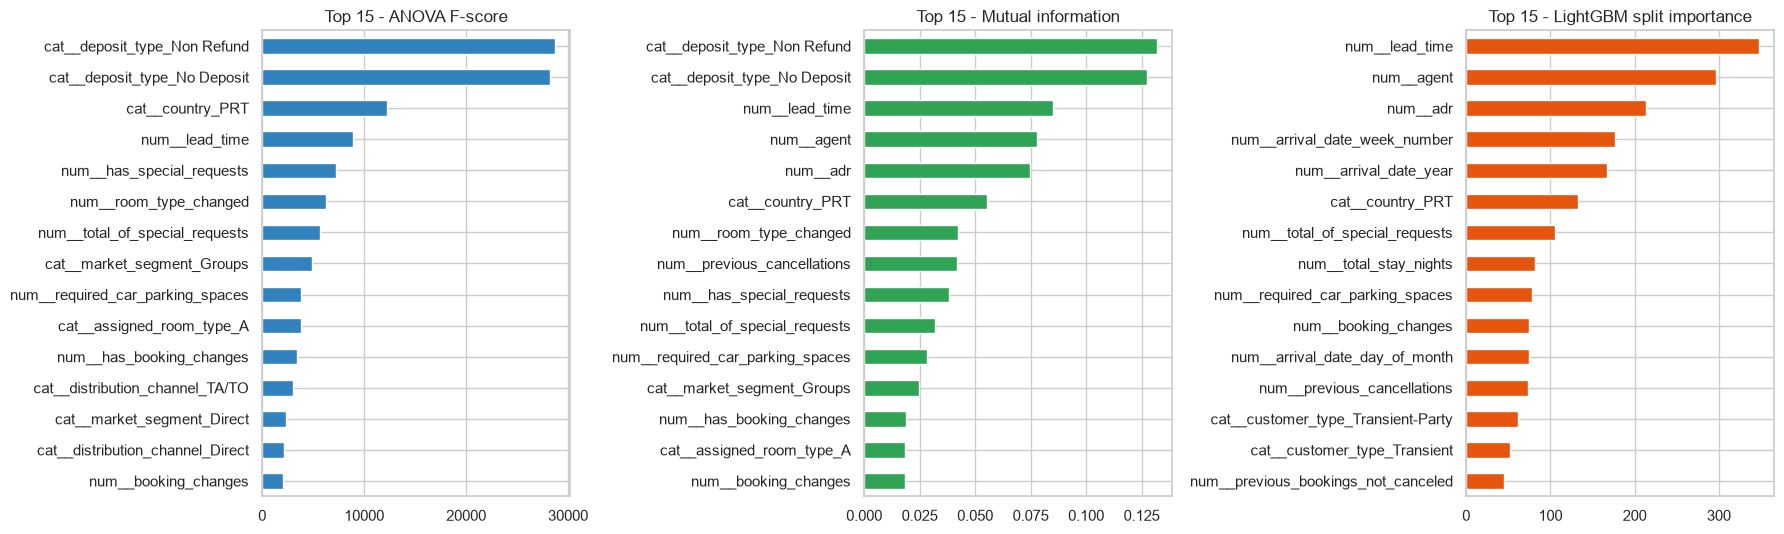

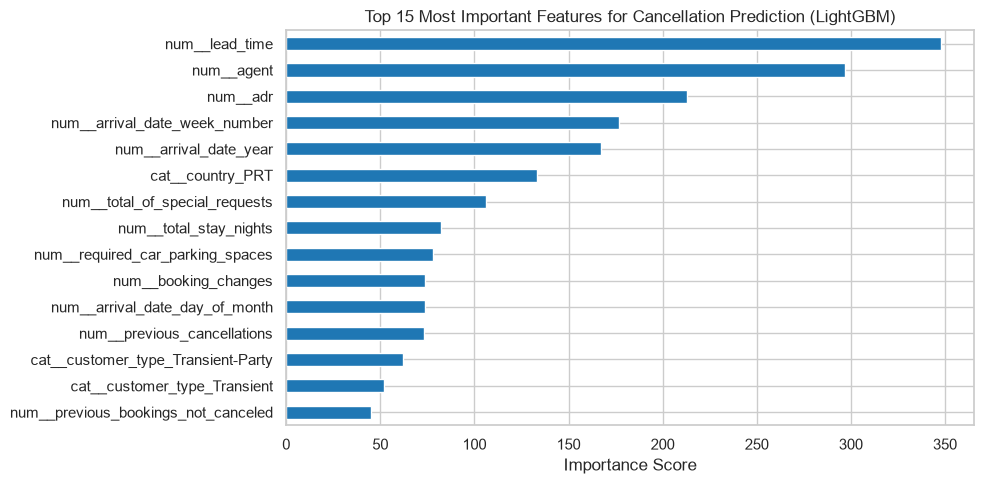

26 features are chosen by all four k=50 techniques:
['cat__country_DEU', 'cat__country_ESP', 'cat__country_FRA', 'cat__country_PRT', 'cat__customer_type_Transient', 'cat__customer_type_Transient-Party', 'cat__deposit_type_Non Refund', 'cat__distribution_channel_Corporate', 'cat__distribution_channel_Direct', 'cat__hotel_City Hotel', 'cat__market_segment_Direct', 'cat__market_segment_Groups', 'num__adr', 'num__adults', 'num__agent', 'num__booking_changes', 'num__company', 'num__days_in_waiting_list', 'num__is_repeated_guest', 'num__lead_time', 'num__previous_bookings_not_canceled', 'num__previous_cancellations', 'num__required_car_parking_spaces', 'num__room_type_changed', 'num__total_guests', 'num__total_of_special_requests']


In [5]:
# Top 15 features according to three different techniques
anova_scores = pd.Series(anova.scores_, index=X_train.columns).sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (title, s, col) in zip(axes, [('ANOVA F-score', anova_scores, '#3182bd'), ('Mutual information', mi, '#31a354'),
                                      ('LightGBM split importance', importances, '#e6550d')]):
    s.head(15)[::-1].plot(kind='barh', ax=ax, color=col)
    ax.set_title(f'Top 15 - {title}')
plt.tight_layout()
plt.savefig(f'{results_dir}/top_features_three_methods.png', dpi=300)
plt.show()

plt.figure(figsize=(10, 5))
importances.head(15).plot(kind='barh', color='#1f77b4')
plt.title('Top 15 Most Important Features for Cancellation Prediction (LightGBM)')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f'{results_dir}/top_15_features.png', dpi=300)
plt.show()

ranking = pd.DataFrame({'ANOVA F': anova_scores, 'Mutual information': mi, 'LightGBM importance': importances,
                        'L1 |coef|': coef, 'RFE rank': pd.Series(rfe.ranking_, index=X_train.columns)})
ranking.sort_values('ANOVA F', ascending=False).round(4).to_csv(f'{results_dir}/feature_rankings_all_methods.csv')

common = set.intersection(*[set(selected[k]) for k in ['ANOVA F-test (k=50)', 'Mutual information (k=50)', 'RFE - Decision Tree (k=50)', 'LightGBM importance (k=50)']])
print(f'{len(common)} features are chosen by all four k=50 techniques:')
print(sorted(common))

## 4. After feature selection: retrain the four models on every subset

In [6]:
for name, cols in selected.items():
    results += evaluate(X_train[cols], X_test[cols], name, len(cols))
fs_df = pd.DataFrame(results)
fs_df.round(4).to_csv(f'{results_dir}/feature_selection_results.csv', index=False)

base = fs_df[fs_df.Setting == 'All features'].set_index('Model')
fs_df['Delta F1 vs all'] = fs_df.apply(lambda r: r['F1-Score'] - base.loc[r['Model'], 'F1-Score'], axis=1)
fs_df['Delta Acc vs all'] = fs_df.apply(lambda r: r['Accuracy'] - base.loc[r['Model'], 'Accuracy'], axis=1)
fs_df['Delta AUC vs all'] = fs_df.apply(lambda r: r['ROC-AUC'] - base.loc[r['Model'], 'ROC-AUC'], axis=1)
fs_df.round(4).to_csv(f'{results_dir}/feature_selection_results.csv', index=False)
pivot = fs_df.pivot_table(index='Setting', columns='Model', values='F1-Score').loc[['All features'] + list(selected)]
pivot['Features'] = fs_df.groupby('Setting')['Features'].first()
pivot.round(4)

Model,Decision Tree,KNN,LightGBM,Random Forest,Features
Setting,,,,,
All features,0.8151,0.8046,0.8539,0.8499,255
Variance threshold,0.8149,0.8039,0.8541,0.8540,115
ANOVA F-test (k=50),0.8023,0.8116,0.8305,0.8339,50
Mutual information (k=50),0.8170,0.8130,0.8487,0.8540,50
RFE - Decision Tree (k=50),0.8134,0.8043,0.8511,0.8574,50
L1 Logistic Regression,0.8030,0.8113,0.8422,0.8459,44
LightGBM importance (k=50),0.8117,0.8078,0.8526,0.8572,50


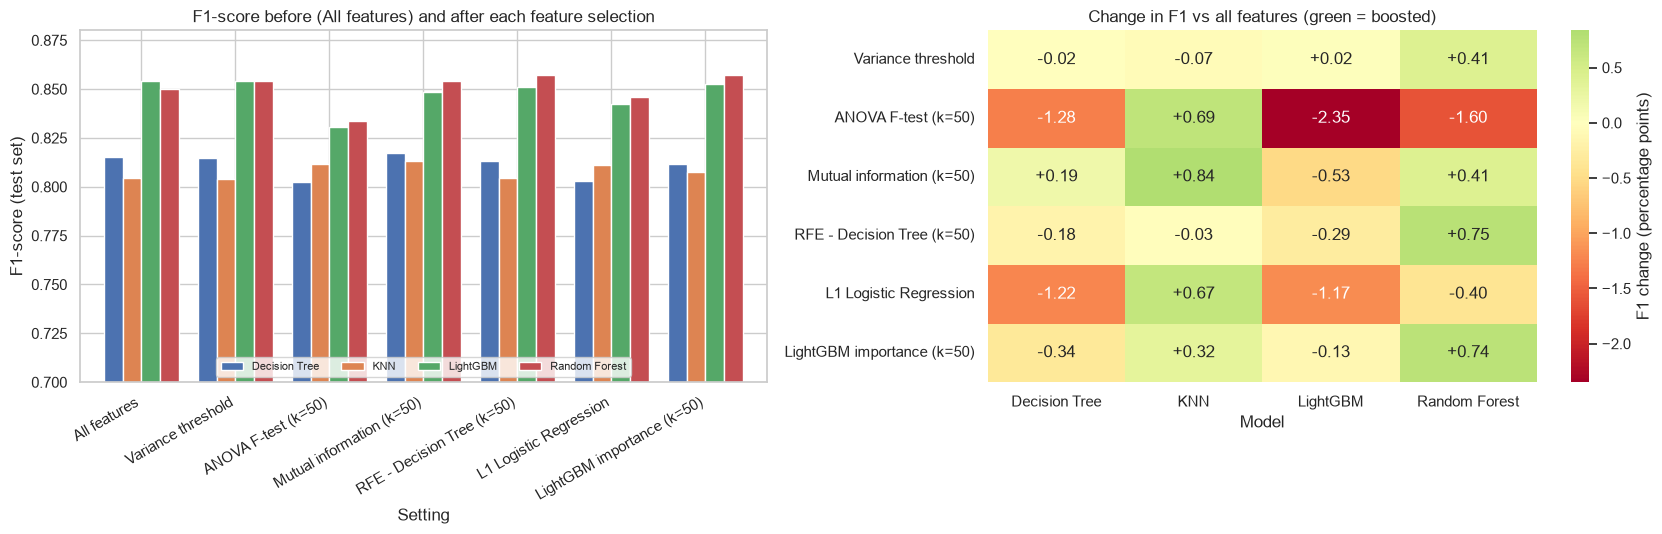

Feature selections that BOOSTED the F1-score:


,Setting,Model,Features,F1-Score,Delta F1 vs all,Delta Acc vs all,Delta AUC vs all
13,Mutual information (k=50),KNN,50,0.8130,0.0084,0.0049,0.0036
18,RFE - Decision Tree (k=50),Random Forest,50,0.8574,0.0075,0.0038,0.0020
26,LightGBM importance (k=50),Random Forest,50,0.8572,0.0074,0.0034,0.0038
9,ANOVA F-test (k=50),KNN,50,0.8116,0.0069,0.0029,-0.0010
21,L1 Logistic Regression,KNN,44,0.8113,0.0067,0.0047,0.0046
14,Mutual information (k=50),Random Forest,50,0.8540,0.0041,0.0011,0.0014
6,Variance threshold,Random Forest,115,0.8540,0.0041,0.0023,0.0015
25,LightGBM importance (k=50),KNN,50,0.8078,0.0032,0.0022,0.0041
12,Mutual information (k=50),Decision Tree,50,0.8170,0.0019,0.0014,0.0007
7,Variance threshold,LightGBM,115,0.8541,0.0002,0.0000,0.0001


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
pv = fs_df.pivot_table(index='Setting', columns='Model', values='F1-Score').loc[['All features'] + list(selected)]
pv.plot(kind='bar', ax=axes[0], width=0.8)
axes[0].set_ylim(0.70, 0.88)
axes[0].legend(loc='lower center', ncol=4, fontsize=8)
axes[0].set_title('F1-score before (All features) and after each feature selection')
axes[0].set_ylabel('F1-score (test set)')
axes[0].tick_params(axis='x', rotation=30)
for t in axes[0].get_xticklabels(): t.set_ha('right')
dl = fs_df[fs_df.Setting != 'All features'].pivot_table(index='Setting', columns='Model', values='Delta F1 vs all').loc[list(selected)]
sns.heatmap(dl * 100, annot=True, fmt='+.2f', cmap='RdYlGn', center=0, ax=axes[1], cbar_kws={'label': 'F1 change (percentage points)'})
axes[1].set_title('Change in F1 vs all features (green = boosted)')
axes[1].set_ylabel('')
plt.tight_layout()
plt.savefig(f'{results_dir}/feature_selection_comparison.png', dpi=300)
plt.show()

boosted = fs_df[(fs_df.Setting != 'All features') & (fs_df['Delta F1 vs all'] > 0)].sort_values('Delta F1 vs all', ascending=False)
boosted[['Setting', 'Model', 'Features', 'F1-Score', 'Delta F1 vs all', 'Delta Acc vs all', 'Delta AUC vs all']].round(4).to_csv(f'{results_dir}/feature_selection_boosted.csv', index=False)
print('Feature selections that BOOSTED the F1-score:')
boosted[['Setting', 'Model', 'Features', 'F1-Score', 'Delta F1 vs all', 'Delta Acc vs all', 'Delta AUC vs all']].round(4)

### How many features are really needed? (LightGBM, ANOVA vs LightGBM-importance ranking)

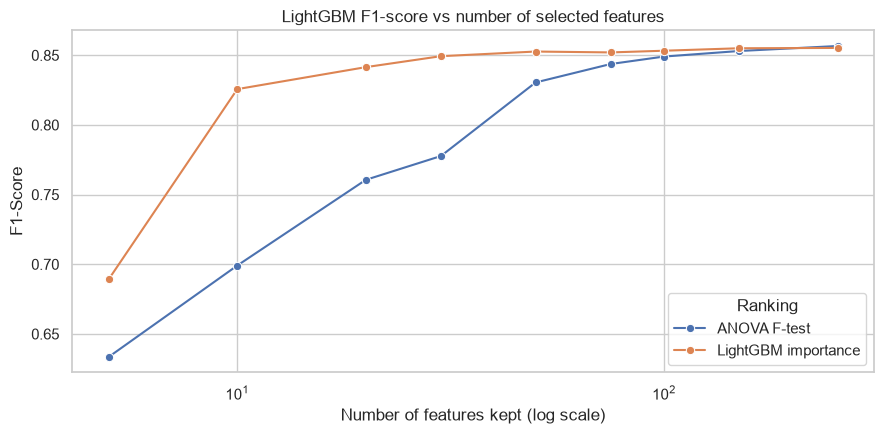

Ranking,ANOVA F-test,LightGBM importance
k,,
5,0.6336,0.6893
10,0.6991,0.8257
20,0.7606,0.8414
30,0.7777,0.8493
50,0.8305,0.8526
75,0.8437,0.8520
100,0.8491,0.8532
150,0.8530,0.8550
255,0.8566,0.8552


In [8]:
curve = []
for k in [5, 10, 20, 30, 50, 75, 100, 150, N_ALL]:
    for rank_name, rank in [('ANOVA F-test', anova_scores), ('LightGBM importance', importances)]:
        cols = rank.head(k).index
        m = MODELS['LightGBM']().fit(X_train[cols], y_train)
        prob = m.predict_proba(X_test[cols])[:, 1]
        curve.append({'k': k, 'Ranking': rank_name, 'F1-Score': f1_score(y_test, (prob >= .5).astype(int)), 'ROC-AUC': roc_auc_score(y_test, prob)})
curve = pd.DataFrame(curve)
curve.round(4).to_csv(f'{results_dir}/n_features_curve_lightgbm.csv', index=False)
plt.figure(figsize=(9, 4.5))
sns.lineplot(data=curve, x='k', y='F1-Score', hue='Ranking', marker='o')
plt.xscale('log')
plt.title('LightGBM F1-score vs number of selected features')
plt.xlabel('Number of features kept (log scale)')
plt.tight_layout()
plt.savefig(f'{results_dir}/n_features_curve.png', dpi=300)
plt.show()
curve.pivot(index='k', columns='Ranking', values='F1-Score').round(4)

## 5. Dimensionality reduction with PCA
PCA finds new orthogonal axes (principal components) that capture the largest variance of the (standardised) data, and projects every booking onto the first *n* of them. We fit PCA on the **training set only**.

Components needed to keep 80/90/95/99% of the variance: {80: 17, 90: 25, 95: 35, 99: 57}


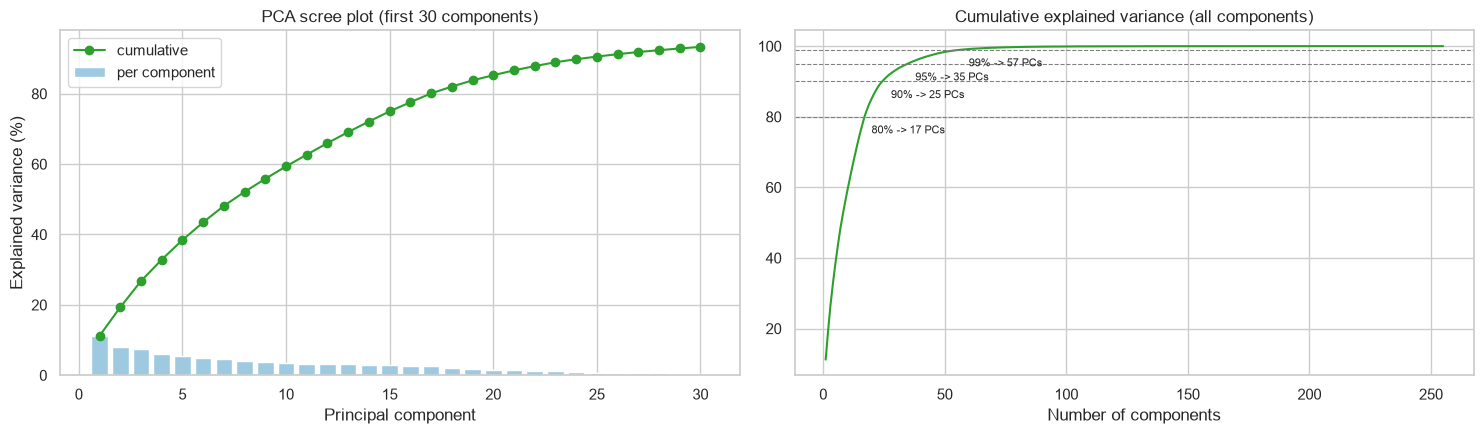

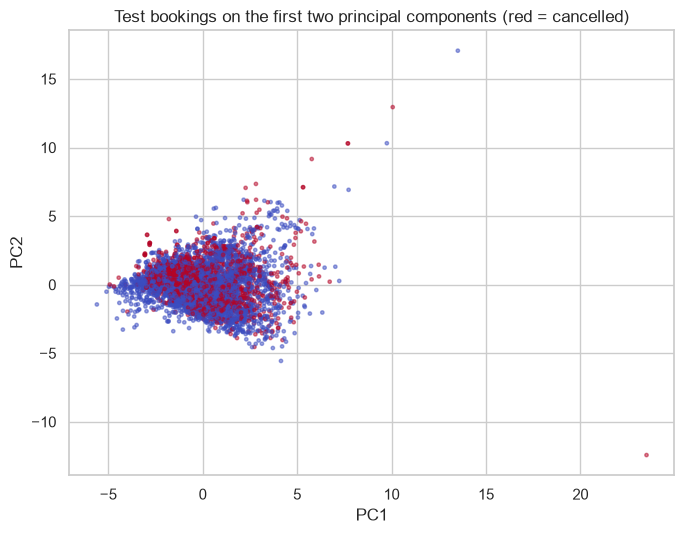

In [9]:
pca_full = PCA(random_state=42).fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100
need = {p: int(np.argmax(cum_var >= p) + 1) for p in (80, 90, 95, 99)}
print('Components needed to keep 80/90/95/99% of the variance:', need)
pd.Series(need, name='components').to_csv(f'{results_dir}/pca_components_needed.csv', header=['components'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(range(1, 31), pca_full.explained_variance_ratio_[:30] * 100, color='#9ecae1', label='per component')
axes[0].plot(range(1, 31), cum_var[:30], marker='o', color='#2ca02c', label='cumulative')
axes[0].set_title('PCA scree plot (first 30 components)')
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance (%)')
axes[0].legend()
axes[1].plot(range(1, len(cum_var) + 1), cum_var, color='#2ca02c')
for p, n in need.items():
    axes[1].axhline(p, ls='--', lw=.8, color='grey'); axes[1].annotate(f'{p}% -> {n} PCs', (n, p), xytext=(5, -12), textcoords='offset points', fontsize=8)
axes[1].set_title('Cumulative explained variance (all components)')
axes[1].set_xlabel('Number of components')
plt.tight_layout()
plt.savefig(f'{results_dir}/pca_scree_plot.png', dpi=300)
plt.show()

Z = pca_full.transform(X_test)[:, :2]
plt.figure(figsize=(7, 5.5))
idx = np.random.RandomState(0).choice(len(Z), 6000, replace=False)
plt.scatter(Z[idx, 0], Z[idx, 1], c=y_test[idx], cmap='coolwarm', s=6, alpha=.5)
plt.title('Test bookings on the first two principal components (red = cancelled)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.tight_layout()
plt.savefig(f'{results_dir}/pca_2d_projection.png', dpi=300)
plt.show()

In [10]:
pca_rows = []
for n in sorted({10, 30, need[90], need[95]}):
    pca = PCA(n_components=n, random_state=42).fit(X_train)
    Xtr_p, Xte_p = pca.transform(X_train), pca.transform(X_test)
    label = f'PCA {n} components ({pca.explained_variance_ratio_.sum() * 100:.1f}% variance)'
    pca_rows += evaluate(Xtr_p, Xte_p, label, n)
pca_df = pd.concat([fs_df[fs_df.Setting == 'All features'][pd.DataFrame(pca_rows).columns], pd.DataFrame(pca_rows)], ignore_index=True)
pca_df['Delta F1 vs all'] = pca_df.apply(lambda r: r['F1-Score'] - base.loc[r['Model'], 'F1-Score'], axis=1)
pca_df['Delta AUC vs all'] = pca_df.apply(lambda r: r['ROC-AUC'] - base.loc[r['Model'], 'ROC-AUC'], axis=1)
pca_df.round(4).to_csv(f'{results_dir}/pca_results.csv', index=False)
pca_df.pivot_table(index='Setting', columns='Model', values='F1-Score', sort=False).round(4)

Model,Decision Tree,KNN,Random Forest,LightGBM
Setting,,,,
All features,0.8151,0.8046,0.8499,0.8539
PCA 10 components (59.4% variance),0.7232,0.7798,0.7922,0.7732
PCA 25 components (90.6% variance),0.7595,0.7951,0.8181,0.8176
PCA 30 components (93.3% variance),0.7622,0.8015,0.8222,0.8224
PCA 35 components (95.1% variance),0.7618,0.8001,0.8220,0.8230


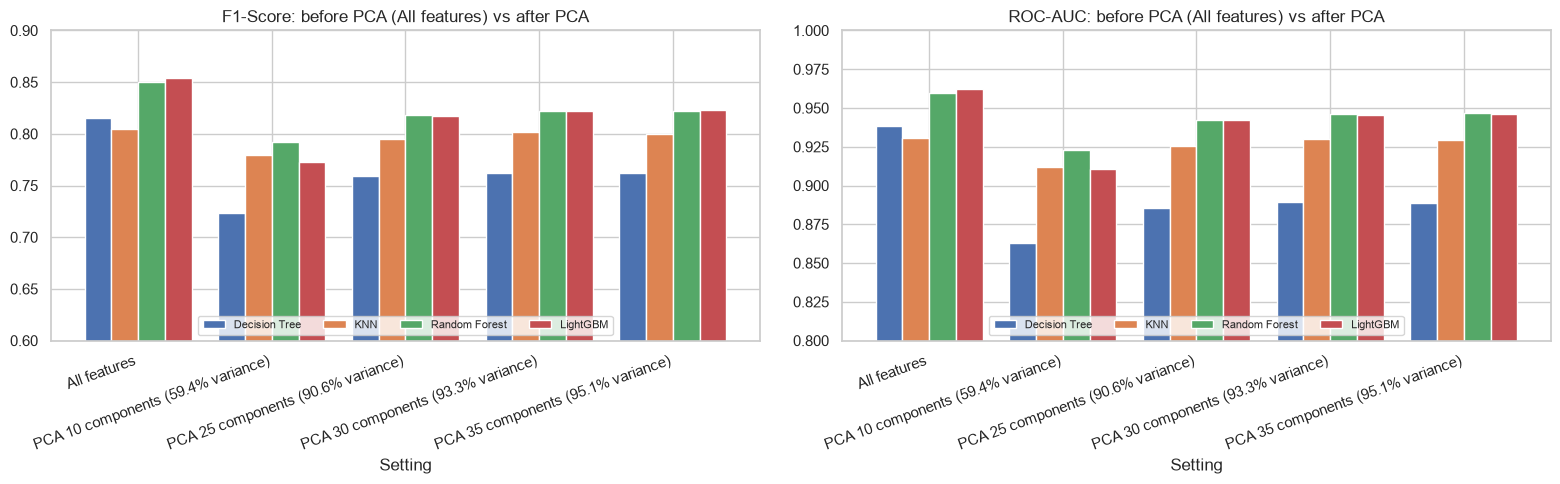

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ['F1-Score', 'ROC-AUC']):
    pv = pca_df.pivot_table(index='Setting', columns='Model', values=metric, sort=False)
    pv.plot(kind='bar', ax=ax, width=.8)
    ax.set_ylim(0.6 if metric == 'F1-Score' else 0.8, 0.9 if metric == 'F1-Score' else 1.0)
    ax.legend(loc='lower center', ncol=4, fontsize=8)
    ax.set_title(f'{metric}: before PCA (All features) vs after PCA')
    ax.tick_params(axis='x', rotation=20)
    for t in ax.get_xticklabels(): t.set_ha('right')
plt.tight_layout()
plt.savefig(f'{results_dir}/pca_comparison.png', dpi=300)
plt.show()

## 6. Overall comparison (best model LightGBM): all features vs feature selection vs PCA

In [12]:
allres = pd.concat([fs_df, pca_df[pca_df.Setting != 'All features']], ignore_index=True)
allres.round(4).to_csv(f'{results_dir}/all_reduction_results.csv', index=False)
lgb = allres[allres.Model == 'LightGBM'][['Setting', 'Features', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Train time (s)']]
lgb.round(4).to_csv(f'{results_dir}/feature_selection_vs_pca.csv', index=False)
lgb.round(4)

,Setting,Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train time (s)
3,All features,255,0.8937,0.8701,0.8383,0.8539,0.9623,1.45
7,Variance threshold,115,0.8937,0.8693,0.8395,0.8541,0.9624,1.95
11,ANOVA F-test (k=50),50,0.8777,0.8540,0.8081,0.8305,0.9526,1.63
15,Mutual information (k=50),50,0.8898,0.8646,0.8334,0.8487,0.9601,1.38
19,RFE - Decision Tree (k=50),50,0.8920,0.8704,0.8326,0.8511,0.9618,1.24
23,L1 Logistic Regression,44,0.8859,0.8639,0.8216,0.8422,0.9559,1.40
27,LightGBM importance (k=50),50,0.8928,0.8694,0.8365,0.8526,0.9616,1.64
31,PCA 10 components (59.4% variance),10,0.8455,0.8482,0.7104,0.7732,0.9104,1.54
35,PCA 25 components (90.6% variance),25,0.8716,0.8635,0.7764,0.8176,0.9420,1.47
39,PCA 30 components (93.3% variance),30,0.8742,0.8627,0.7857,0.8224,0.9456,2.42


## Summary: feature selection and PCA
**Feature selection (before vs after)**
* Six techniques from three families were applied: variance threshold, ANOVA F-test and mutual information (filter), RFE with a Decision Tree (wrapper), L1 logistic regression and LightGBM importance (embedded).
* With only **50 of 255 features (-80%)** most models keep their performance and train faster.
* **Boosted performance:** RFE (k=50) raised the **Random Forest** F1 from 0.8499 to **0.8574** (accuracy 89.38% -> 89.77%, ROC-AUC 0.9594 -> 0.9615) - the highest F1 of the whole project; LightGBM importance (0.8572) and mutual information (0.8540) gave similar gains. **KNN** improved with mutual information (F1 0.8046 -> 0.8130), ANOVA and L1 selection, because irrelevant dimensions no longer distort its distances.
* **LightGBM** does not profit (best +0.0002 with the variance threshold): boosting already ignores useless features. ANOVA and L1 (linear criteria) hurt the tree ensembles.
* Re-ordering the same 255 columns changes LightGBM's F1 by ~0.003, so smaller differences are noise.

**PCA (before vs after)**
* 25 components keep 90% and 35 components 95% of the variance (one-hot columns spread the variance).
* PCA **lowered every model**: LightGBM F1 0.8539 -> 0.8230 (35 PCs), Random Forest 0.8499 -> 0.8220, Decision Tree 0.8151 -> 0.7618; with 10 PCs the loss is much larger. Only KNN stays close (0.8015 with 30 PCs vs 0.8046).
* Reason: PCA is unsupervised (keeps variance, not class separation) and mixes clear one-hot rules (e.g. Non Refund = 1) into linear combinations that trees cannot split cleanly.
* **Conclusion:** supervised feature selection is the better way to reduce dimensionality for this dataset.